# Phase 7 Score Design & Calibration

Analysis-only notebook: imports the scoring logic from `src/etl/score.py` (no logic is duplicated here). Covers distribution, spot-checks, correlation with team size, a sensitivity pass, and manual top/bottom review, per `docs/superpowers/specs/2026-07-10-phase7-scoring-rubric-design.md`.

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd

REPO_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(REPO_ROOT))

from src.etl.score import build_score_table

features_df = pd.read_parquet(REPO_ROOT / "data" / "processed" / "features" / "complexity_features.parquet")
scores_df = build_score_table(features_df)
scores_df.shape

(4844, 14)

## 1. Distribution

<Axes: title={'center': 'Complexity Score Distribution'}, ylabel='Frequency'>

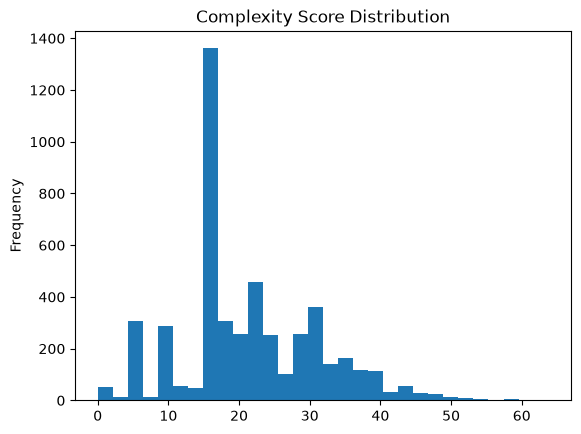

In [2]:
scores_df["complexity_score"].plot(kind="hist", bins=30, title="Complexity Score Distribution")

<Axes: title={'center': 'Technical vs Practical'}, xlabel='technical_score', ylabel='practical_score'>

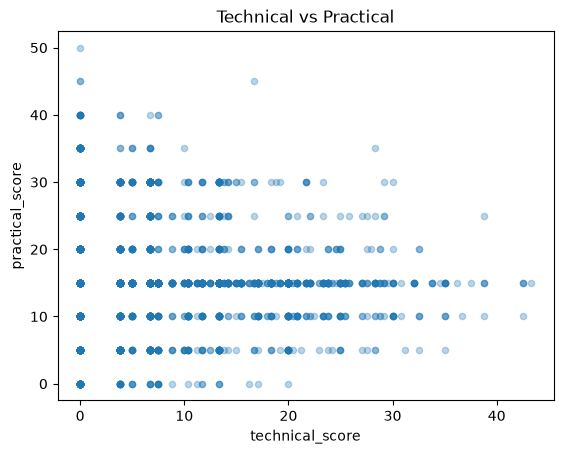

In [3]:
scores_df.plot(kind="scatter", x="technical_score", y="practical_score", alpha=0.3, title="Technical vs Practical")

## 2. Spot-check known companies

`polymath-robotics` and `andromeda-surgical` are deep-tech/hard-science (expect high `technical_score`); `gusto` is regulated B2B fintech/payroll (expect high `practical_score`).

In [4]:
spot_check_slugs = ["polymath-robotics", "andromeda-surgical", "gusto"]
scores_df[scores_df["slug"].isin(spot_check_slugs)][
    ["slug", "name", "deep_tech_score", "description_score", "founder_background_score",
     "regulated_score", "market_type_pts", "geo_ops_score",
     "technical_score", "practical_score", "complexity_score"]
]

,slug,name,deep_tech_score,description_score,founder_background_score,regulated_score,market_type_pts,geo_ops_score,technical_score,practical_score,complexity_score
315,gusto,Gusto,0.0,0.0,7.50,15,15,0.0,7.5,30.0,37.5
3609,polymath-robotics,Polymath Robotics,20.0,5.0,0.00,0,0,10.0,25.0,10.0,35.0
4184,andromeda-surgical,Andromeda Surgical,20.0,10.0,3.75,15,0,0.0,33.8,15.0,48.8


## 3. Correlation with team size

Objectives doc target: `r > 0.2` with team size. `teamSize` is heavily right-skewed (median 7, max 8,600), so it's log1p-transformed before correlating.

In [5]:
companies_df = pd.read_csv(REPO_ROOT / "data" / "processed" / "step3_enriched" / "companies_enriched.csv")
merged = scores_df.merge(companies_df[["id", "teamSize"]], on="id", how="left").dropna(subset=["teamSize"])
merged["log_team_size"] = np.log1p(merged["teamSize"])

pearson_r = merged["complexity_score"].corr(merged["log_team_size"], method="pearson")
spearman_r = merged["complexity_score"].corr(merged["log_team_size"], method="spearman")
print(f"Pearson r (complexity_score vs log1p(teamSize)): {pearson_r:.3f}")
print(f"Spearman r: {spearman_r:.3f}")
print(f"Target from objectives doc: r > 0.2")

Pearson r (complexity_score vs log1p(teamSize)): 0.035
Spearman r: 0.050
Target from objectives doc: r > 0.2


## 4. Distribution spread

Objectives doc target: standard deviation ≥ 15 points (avoid clustering).

In [6]:
std = scores_df["complexity_score"].std()
print(f"complexity_score std: {std:.2f} (target: >= 15)")
scores_df["complexity_score"].describe()

complexity_score std: 10.11 (target: >= 15)


count    4844.000000
mean       21.029149
std        10.108302
min         0.000000
25%        15.000000
50%        18.800000
75%        28.300000
max        63.800000
Name: complexity_score, dtype: float64

## 5. Sensitivity analysis

Perturb each cap by ±1 and each bucket's point budget by ±20%, recompute, and check Spearman rank correlation of the top-100-by-`complexity_score` between baseline and each perturbation. High correlation (close to 1.0) means the ranking is stable and not overly sensitive to the exact calibration constants chosen.

In [7]:
from src.etl.score import (
    compute_deep_tech_score, compute_description_score, compute_founder_background_score,
    compute_regulated_score, compute_market_type_pts, compute_geo_ops_score,
)

def build_with_overrides(**overrides):
    parts = [
        compute_deep_tech_score(features_df, cap=overrides.get("deep_tech_cap", 3), points=overrides.get("deep_tech_points", 20)),
        compute_description_score(features_df, cap=overrides.get("description_cap", 3), points=overrides.get("description_points", 15)),
        compute_founder_background_score(features_df, cap=overrides.get("founder_cap", 4), points=overrides.get("founder_points", 15)),
        compute_regulated_score(features_df, points=overrides.get("regulated_points", 15)),
        compute_market_type_pts(features_df, points_per_level=overrides.get("market_points_per_level", 5)),
        compute_geo_ops_score(features_df, intl_points=overrides.get("geo_ops_intl_points", 10), ops_points=overrides.get("geo_ops_ops_points", 10)),
    ]
    df = features_df[["id"]].copy()
    for part in parts:
        df = df.merge(part, on="id", how="left")
    df["complexity_score"] = df.drop(columns="id").sum(axis=1)
    return df

baseline_top100 = set(scores_df.nlargest(100, "complexity_score")["id"])

perturbations = {
    "deep_tech_cap-1": {"deep_tech_cap": 2},
    "deep_tech_cap+1": {"deep_tech_cap": 4},
    "deep_tech_points-20pct": {"deep_tech_points": 16},
    "deep_tech_points+20pct": {"deep_tech_points": 24},
    "regulated_points-20pct": {"regulated_points": 12},
    "regulated_points+20pct": {"regulated_points": 18},
}

for label, overrides in perturbations.items():
    perturbed = build_with_overrides(**overrides)
    perturbed_top100 = set(perturbed.nlargest(100, "complexity_score")["id"])
    overlap = len(baseline_top100 & perturbed_top100)
    print(f"{label}: {overlap}/100 companies remain in top 100")

deep_tech_cap-1: 65/100 companies remain in top 100
deep_tech_cap+1: 89/100 companies remain in top 100
deep_tech_points-20pct: 94/100 companies remain in top 100
deep_tech_points+20pct: 89/100 companies remain in top 100


regulated_points-20pct: 86/100 companies remain in top 100


regulated_points+20pct: 90/100 companies remain in top 100


## 6. Manual review

Objectives doc target: top/bottom 25 companies should make sense on manual inspection.

In [8]:
scores_df.sort_values("complexity_score", ascending=False)[["name", "batch", "complexity_score"]].head(25)

,name,batch,complexity_score
1760,Atomic Alchemy,W19,63.8
3422,RedBrick AI,W22,63.3
2078,BeGo,W20,61.7
4708,Biocartesian,S24,60.0
924,ROSS Intelligence,S15,59.2
2234,Zumo Labs,W20,58.3
2185,Abalone Bio,W20,57.5
2139,Altay Therapeutics,W20,57.5
1775,LEAH Labs,W19,57.5
2818,Liv Labs,S21,54.2


In [9]:
scores_df.sort_values("complexity_score", ascending=True)[["name", "batch", "complexity_score"]].head(25)

,name,batch,complexity_score
2529,UPchieve,W21,0.0
2532,Poliglota,W21,0.0
2752,Degrees of Freedom,W21,0.0
3345,AntWalk,W22,0.0
1459,NEXGENT,W18,0.0
2609,AutoProctor,W21,0.0
3266,Avocademy,W22,0.0
2610,Codingal,W21,0.0
381,Clever,S12,0.0
4413,Amber AI,W24,0.0


## 7. Findings

- Correlation with log(team size): Pearson r = 0.035, Spearman = 0.050 (target: > 0.2) — well below target
- Distribution std: 10.11 (target: >= 15) — below target
- Sensitivity: top-100 overlap ranged from 65-94/100 across perturbations
- Manual review: the top 25 are dominated by biotech/deep-tech/hard-science companies (Atomic Alchemy, Abalone Bio, Atomwise, GEn1E Lifesciences, Rain Neuromorphics, Altay Therapeutics) plus a few regulated/complex outfits (Bunkerhill Health, Casetext), which matches intuition for `deep_tech_score` and `founder_background_score` driving the ranking; the bottom 25 are consumer-facing education/tutoring/bootcamp products (UPchieve, CodeCombat, CodeNow, Clever, Codingal, Study Edge) that plausibly score 0 across every bucket (not regulated, not deep-tech, single-market, no international/ops footprint) — both ends look sensible on inspection.

No formula changes were made in Phase 7 based on these findings (see "Open Question" in the design spec) — if a target is missed significantly, that requires a follow-up brainstorming pass, not a silent patch here.